In [2]:
import scimap as sm

Running SCIMAP  2.3.4


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import anndata as ad
import scanpy as sc

In [2]:
import os
os.getcwd()

'C:\\Users\\tpeng\\Notebook_home_250910'

In [3]:
adata = sc.read ('C:\\Users\\tpeng\\adata_files\\Xenium_Proseq_pt5_lesion_neighborhood_261009.h5ad')
adata

AnnData object with n_obs × n_vars = 11475 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3', 'imageid', 'spatial_lda_kmeans6'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'spatial_lda', 'spatial_lda_probability', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [32]:
# run the LDA tool
adata = sm.tl.spatial_lda(adata, phenotype='Cell_label_L3', method='radius', radius=80, label='spatial_lda')

Processing: ['Pt5_lesion_proseq']
Identifying neighbours within 80 pixels of every cell
Pre-Processing Spatial LDA
Training Spatial LDA
Calculating the Coherence Score

Coherence Score:  0.34738188180252416
Gathering the latent weights


C:\Users\tpeng\anaconda3\envs\scimap\lib\site-packages\scimap\tools\spatial_lda.py:270: ImplicitModificationWarning:

Trying to modify attribute `._uns` of view, initializing view as actual.



In [33]:
# note that the df_name parameter needs to be the same as the label used in the previous step.
adata = sm.tl.spatial_cluster(adata, df_name='spatial_lda', method='kmeans', k=6, label='spatial_lda_kmeans6')

Kmeans clustering


In [34]:
adata

AnnData object with n_obs × n_vars = 11475 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'SampleID', 'Tissue_type', 'PatientID', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3', 'imageid', 'spatial_lda_kmeans6'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap', 'spatial_lda', 'spatial_lda_probability'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors

In [42]:
# Let's visualize the results.

from matplotlib import rcParams
FIGSIZE = (16, 16)
my_colors = {'0':'lightsteelblue', '1':'purple', '2':'goldenrod', '3':'lightsalmon', '4':'olive','5' : 'rosybrown'}

sm.pl.spatial_scatterPlot(adata, colorBy='spatial_lda_kmeans6', s =4, alpha = 0.8,  dpi = 300,customColors = my_colors,
                          fileName='scatterplot_pt5_lesion_IC+kera_6clusters_261009.png', saveDir="./figures")

Saved plot to ./figures\scatterplot_pt5_lesion_IC+kera_6clusters_261009.png


In [52]:
adata.write_h5ad ('C:\\Users\\tpeng\\\Documents\\Spatial\\adata_files\\Xenium_Proseq_pt5_lesion_neighborhood_261009.h5ad')

## Generate heatmap #

In [4]:
adata = sc.read ('C:\\Users\\tpeng\\adata_files\\Xenium_Proseq_pt5_lesion_neighborhood_261009.h5ad')
adata

AnnData object with n_obs × n_vars = 11475 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3', 'imageid', 'spatial_lda_kmeans6'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'spatial_lda', 'spatial_lda_probability', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [5]:
df = adata.obs.groupby("Cell_label_L3")["spatial_lda_kmeans6"].value_counts().unstack()
df

C:\Users\tpeng\AppData\Local\Temp\ipykernel_14064\545790267.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = adata.obs.groupby("Cell_label_L3")["spatial_lda_kmeans6"].value_counts().unstack()


spatial_lda_kmeans6,0,1,2,3,4,5
Cell_label_L3,,,,,,
Basal keratinocyte_lesion,2,1,211,23,1,139
Basal keratinocyte_non-lesion,5,0,166,0,63,4
CD4 T cell_FOXP3+,561,74,1,8,43,27
CD4 T cell_GZMBhi,271,165,0,11,33,30
CD4 T cell_GZMBlow,817,25,2,3,104,20
CD8 T cell_GZMBhi,131,38,2,5,11,24
CD8 T cell_GZMBlow,546,39,1,1,81,4
DC_LAMP3+,455,417,4,23,68,22
Granulosum keratinocyte_CXCL8+,1,0,541,36,2,36


In [6]:
frequency_table = (df / df.sum())*100

pd.options.display.float_format = '{:.2f}'.format

In [7]:
df.shape

(17, 6)

In [8]:
# Define your desired custom order
custom_order = ['2', '5', '1','3','4','0']
frequency_table = frequency_table[custom_order]

In [9]:
frequency_table.columns = ['N0','N1','N2','N3','N4','N5']

In [10]:
# Replace specific elements using a dictionary
frequency_table.index = frequency_table.index.rename_categories({

                                                       'Basal keratinocyte_lesion' : 'Basal keratinocyte_ulc',
                                                       'Basal keratinocyte_non-lesion' : 'Basal keratinocyte_adj'})
frequency_table

,N0,N1,N2,N3,N4,N5
Cell_label_L3,,,,,,
Basal keratinocyte_ulc,14.23,18.03,0.07,1.97,0.17,0.03
Basal keratinocyte_adj,11.19,0.52,0.00,0.00,10.55,0.08
CD4 T cell_FOXP3+,0.07,3.50,5.29,0.68,7.20,9.26
CD4 T cell_GZMBhi,0.00,3.89,11.79,0.94,5.53,4.47
CD4 T cell_GZMBlow,0.13,2.59,1.79,0.26,17.42,13.49
CD8 T cell_GZMBhi,0.13,3.11,2.72,0.43,1.84,2.16
CD8 T cell_GZMBlow,0.07,0.52,2.79,0.09,13.57,9.01
DC_LAMP3+,0.27,2.85,29.81,1.97,11.39,7.51
Granulosum keratinocyte_CXCL8+,36.48,4.67,0.00,3.08,0.34,0.02


In [11]:
list2 = ['Granulosum keratinocyte_CXCL8+',
 'Spinosum keratinocyte_CXCL8+',
 'Basal keratinocyte_ulc',
 'Spinosum keratinocyte_KRT2+',
 'Basal keratinocyte_adj',
 'CD8 T cell_GZMBhi',
 'CD4 T cell_GZMBhi',
 'CD8 T cell_GZMBlow',
 'CD4 T cell_GZMBlow',
 'CD4 T cell_FOXP3+',
 'NK cell',
 'Mono_IL3RA+',
 'Mono_ISGhi','Mono_ISGlow',
 'Mac_ISGlow',
 'DC_LAMP3+',
 'PDC']
len(list2)

17

In [12]:
# Define your desired custom order
custom_order = list2
# Reorder the index based on the list
frequency_table = frequency_table.reindex(custom_order)

In [13]:
frequency_table.index = ['Granu kera_CXCL8+',
 'Spino kera_CXCL8+',
 'Basa kera_ulc',
 'Spino kera_KRT2+',
 'Basa kera_adj',
 'CD8 T_GZMBhi',
 'CD4 T_GZMBhi',
 'CD8 T_GZMBlow','CD4 T_GZMBlow',
 'CD4 T_FOXP3+',
 'NK',
 'Mono_IL3RA+',
 'Mono_ISGhi','Mono_ISGlow',
 'Mac_ISGlow',
 'DC_LAMP3+',
 'PDC']
frequency_table

,N0,N1,N2,N3,N4,N5
Granu kera_CXCL8+,36.48,4.67,0.00,3.08,0.34,0.02
Spino kera_CXCL8+,15.17,0.65,0.00,0.00,0.00,0.00
Basa kera_ulc,14.23,18.03,0.07,1.97,0.17,0.03
Spino kera_KRT2+,15.24,1.82,0.00,0.00,0.00,0.00
Basa kera_adj,11.19,0.52,0.00,0.00,10.55,0.08
CD8 T_GZMBhi,0.13,3.11,2.72,0.43,1.84,2.16
CD4 T_GZMBhi,0.00,3.89,11.79,0.94,5.53,4.47
CD8 T_GZMBlow,0.07,0.52,2.79,0.09,13.57,9.01
CD4 T_GZMBlow,0.13,2.59,1.79,0.26,17.42,13.49
CD4 T_FOXP3+,0.07,3.50,5.29,0.68,7.20,9.26


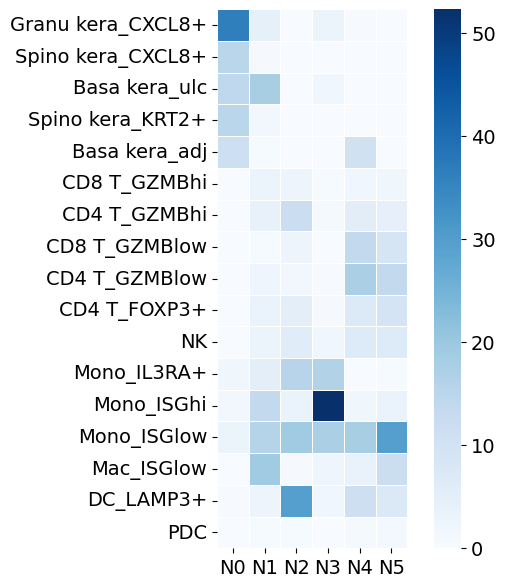

In [14]:
plt.figure(figsize=(7, 7)) # Optional: Adjust the size of the plot

ax = sns.heatmap(
    data= frequency_table,          # The DataFrame/data to plot
    annot=False,               # Display the correlation values on the heatmap
    cmap='Blues',          # The color map (e.g., 'viridis', 'plasma', 'coolwarm')
    fmt=".2f",                # String format for annotation values
    linewidths=.5,            # Space between cells
    annot_kws={"fontsize": 16}, square = True
)


# Set the font size for the x and y tick labels
ax.set_xticklabels(ax.get_xticklabels(), fontsize=14)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=14)


# Access the colorbar and set the size of its tick labels
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=14) # 'labelsize' parameter sets the tick label font size

plt.show()

In [15]:
adata.obs.imageid.unique()

['Pt5_lesion_proseq']
Categories (1, object): ['Pt5_lesion_proseq']